## DEVELOPMENT OF ENHANCED PERSONALIZED RATING RECOMMENDATIONS FOR STREAMING SERVICES THROUGH COLLABORATIVE FILTERING TECHNIQUES.
We begin by loading the dataset and displaying the first few rows to get an overview. After that, we'll conduct EDA to uncover key insights and statistical properties of the data.

Let's proceed with these steps:

Load the dataset.
Display the first few rows.
Check for missing values.
Examine the basic statistics.
Explore the distribution of key features.
I'll begin by executing the initial code for these steps.

The dataset contains information about various shows and movies on Netflix, with columns such as show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, and description

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, linregress
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

In [33]:
df_netflix = pd.read_csv('netflixdataset.csv')

In [34]:
df_netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [35]:
df_netflix.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7281 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


In [5]:
df_netflix.shape

(7787, 12)

### Check for missing values

In [8]:
missing_values = df_netflix.isnull().sum()
print("Missing values:\n", missing_values)

Missing values:
 show_id            0
type               0
title              0
director        2389
cast             718
country          506
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64


In [9]:
df_netflix.dropna()

df_netflix.shape

(7787, 12)

### Display basic statistics

In [14]:
basic_stats = df_netflix.describe(include='all')

missing_values, basic_stats

(show_id            0
 type               0
 title              0
 director        2389
 cast             718
 country          506
 date_added        10
 release_year       0
 rating             7
 duration           0
 listed_in          0
 description        0
 dtype: int64,
        show_id   type title                director                cast  \
 count     7787   7787  7787                    5398                7069   
 unique    7787      2  7787                    4049                6831   
 top         s1  Movie    3%  Raúl Campos, Jan Suter  David Attenborough   
 freq         1   5377     1                      18                  18   
 mean       NaN    NaN   NaN                     NaN                 NaN   
 std        NaN    NaN   NaN                     NaN                 NaN   
 min        NaN    NaN   NaN                     NaN                 NaN   
 25%        NaN    NaN   NaN                     NaN                 NaN   
 50%        NaN    NaN   NaN         

### EDA to uncover key insights and statistical properties 

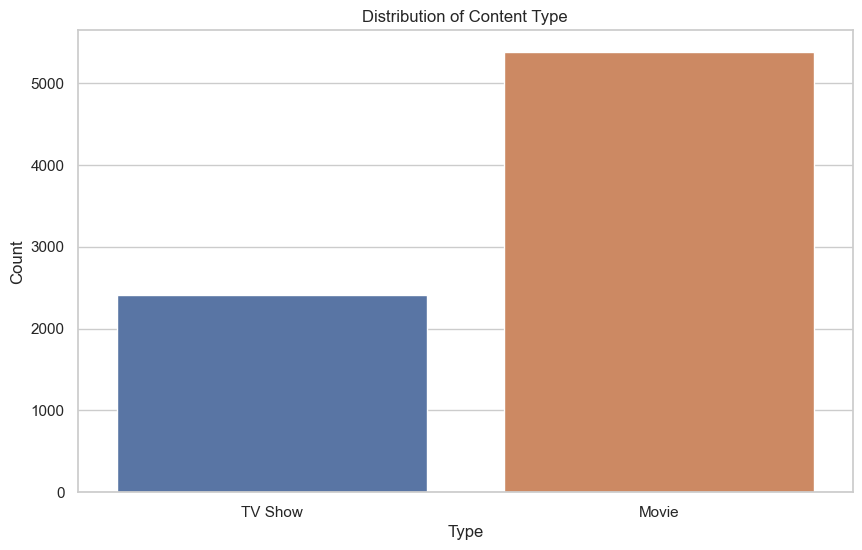

In [16]:
sns.set(style="whitegrid")


# Plot the distribution of 'type'
plt.figure(figsize=(10, 6))
sns.countplot(data=df_netflix, x='type')
plt.title('Distribution of Content Type')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()

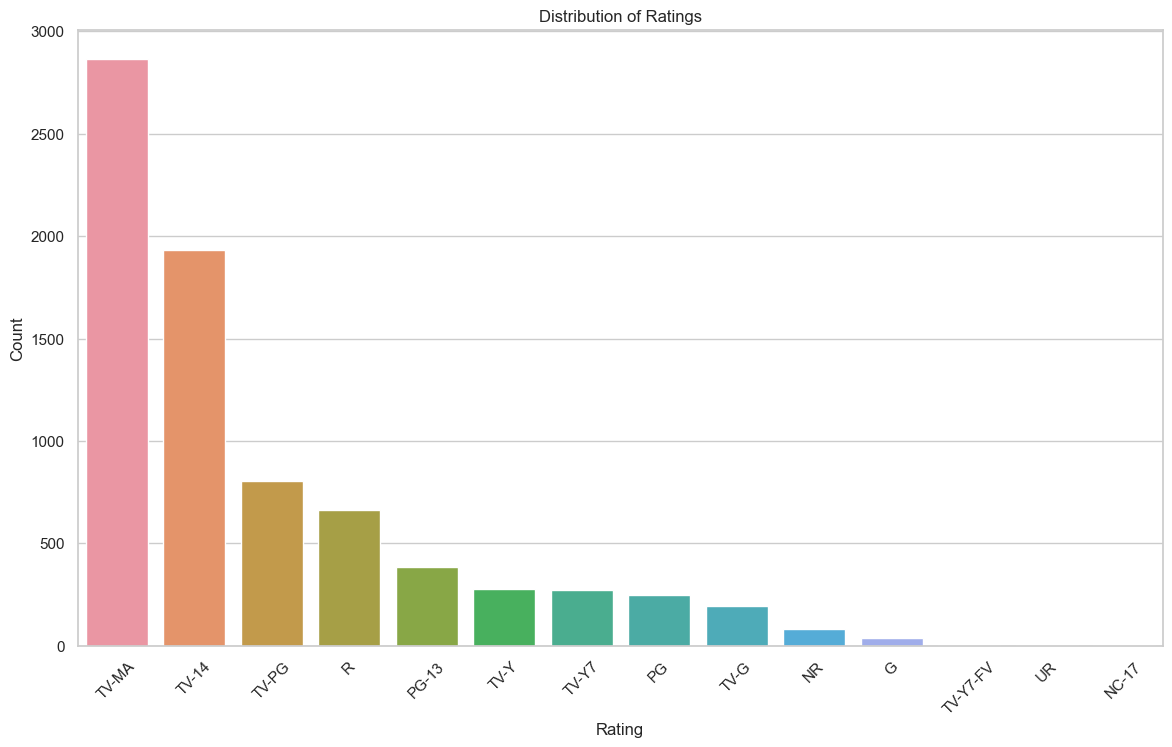

In [17]:
# Plot the distribution of 'rating'
plt.figure(figsize=(14, 8))
sns.countplot(data=df_netflix, x='rating', order=df_netflix['rating'].value_counts().index)
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

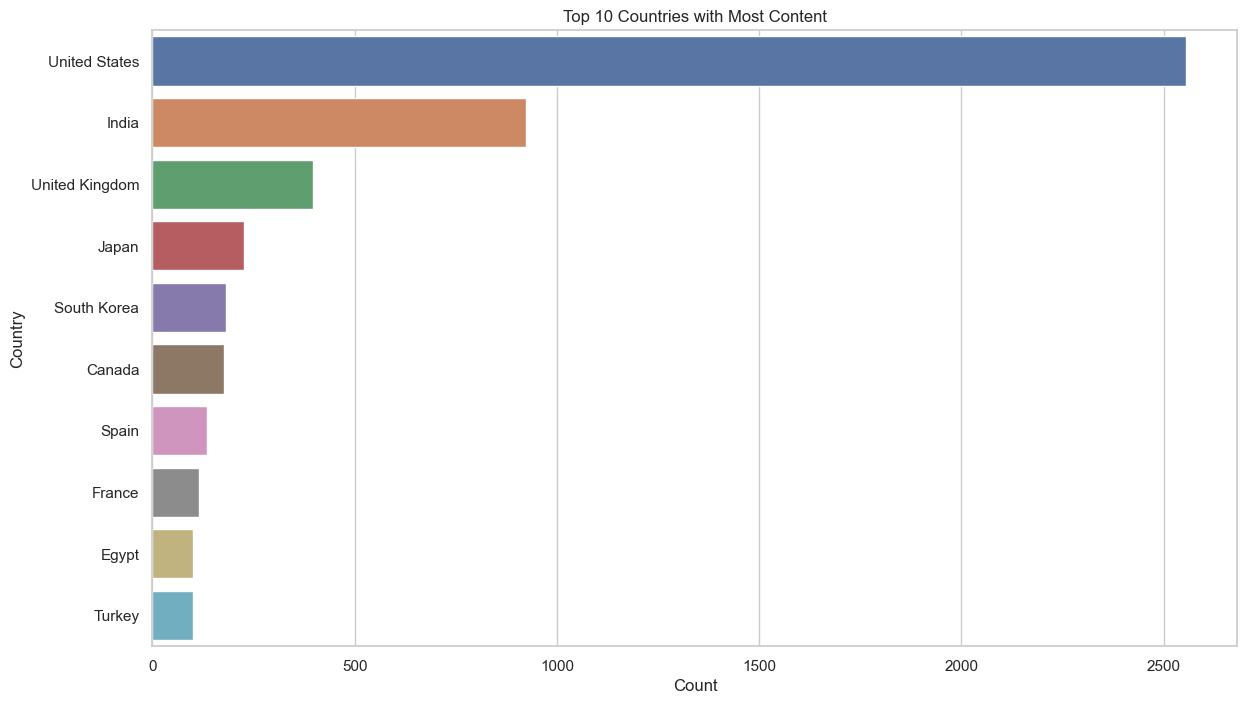

In [19]:
# Plot the distribution of 'country' (top 10 countries)
plt.figure(figsize=(14, 8))
top_countries = df_netflix['country'].value_counts().nlargest(10)
sns.barplot(y=top_countries.index, x=top_countries.values)
plt.title('Top 10 Countries with Most Content')
plt.xlabel('Count')
plt.ylabel('Country')
plt.show()

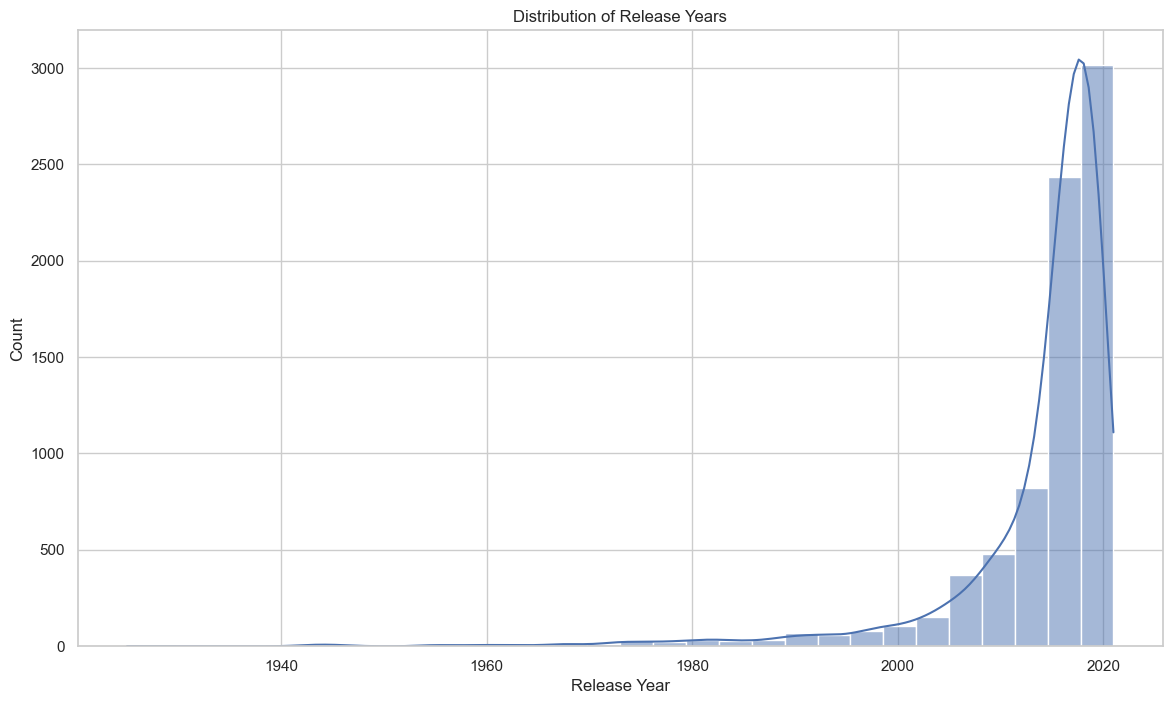

In [20]:
# Plot the distribution of 'release_year'
plt.figure(figsize=(14, 8))
sns.histplot(data=df_netflix, x='release_year', bins=30, kde=True)
plt.title('Distribution of Release Years')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.show()

### Hypothesis 1: There is a significant difference in the average release year of Movies vs. TV Shows.

In [25]:
movies = df_netflix[df_netflix['type'] == 'Movie']
tv_shows = df_netflix[df_netflix['type'] == 'TV Show']


#### Perform a t-test to compare the average release year of Movies and TV Shows

In [26]:
t_stat, p_value = ttest_ind(movies['release_year'], tv_shows['release_year'])

t_stat, p_value

(-15.471646887498206, 3.3215422215256953e-53)

### Hypothesis 2: The average rating for content produced in the United States is different from that produced in other countries.

In [10]:
print("Missing values in 'rating':", df_netflix['rating'].isnull().sum())
print("Missing values in 'country':", df_netflix['country'].isnull().sum())

Missing values in 'rating': 7
Missing values in 'country': 506


In [11]:
df_netflix['rating'].fillna('Unrated', inplace=True)
df_netflix['country'].fillna('Unknown', inplace=True)

### 

In [14]:
rating_mapping = {
    'TV-MA': 1,
    'TV-14': 2,
    'TV-PG': 3,
    'R': 4,
    'PG-13': 5,
    'TV-Y7': 6,
    'TV-Y': 7,
    'NR': 8,
    'PG': 9,
    'G': 10,
    'TV-G': 11,
    'Unrated': 12
}

df_netflix['numeric_rating'] = df_netflix['rating'].map(rating_mapping)
print(df_netflix[['rating', 'numeric_rating']].head())

  rating  numeric_rating
0  TV-MA             1.0
1  TV-MA             1.0
2      R             4.0
3  PG-13             5.0
4  PG-13             5.0


In [15]:
# Separate the data into two groups: US content and Non-US content
us_content = df_netflix[df_netflix['country'] == 'United States']
non_us_content = df_netflix[df_netflix['country'] != 'United States']

In [16]:
t_stat, p_value = ttest_ind(us_content['numeric_rating'], non_us_content['numeric_rating'])

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: nan
P-value: nan


In [18]:
alpha = 0.05
if p_value < alpha:
    print("We reject the null hypothesis. There is a significant difference in the average ratings between US and Non-US content.")
else:
    print("We fail to reject the null hypothesis. There is no significant difference in the average ratings between US and Non-US content.")

We fail to reject the null hypothesis. There is no significant difference in the average ratings between US and Non-US content.


### Hypothesis 3: The number of new releases added to Netflix has significantly increased over the years.

In [19]:
df_netflix['date_added'] = pd.to_datetime(df_netflix['date_added'], errors='coerce')
df_netflix['year_added'] = df_netflix['date_added'].dt.year
df_netflix = df_netflix.dropna(subset=['year_added'])

#### Group by 'year_added' and count the number of new releases

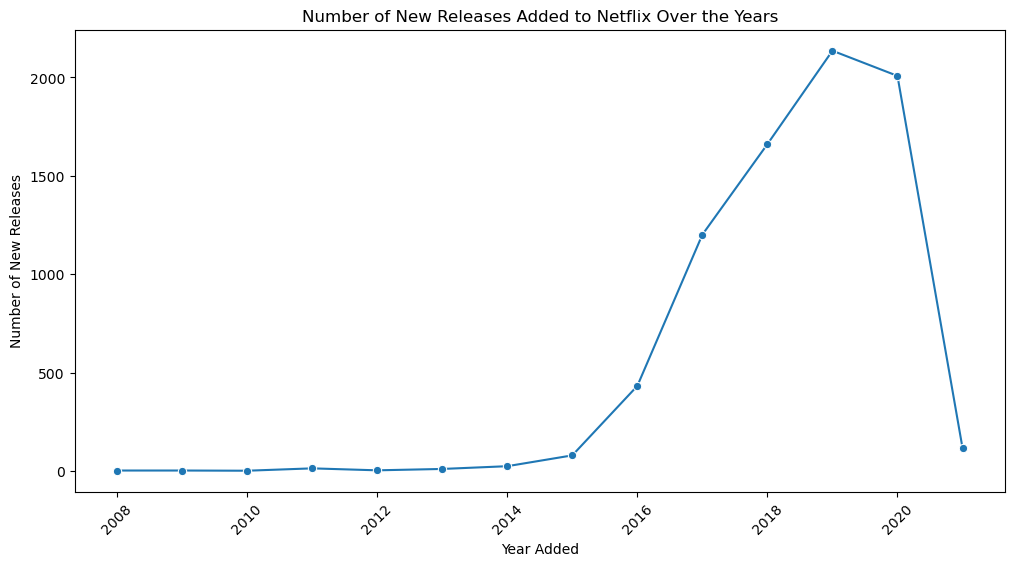

In [20]:
new_releases_per_year = df_netflix.groupby('year_added').size().reset_index(name='count')


plt.figure(figsize=(12, 6))
sns.lineplot(data=new_releases_per_year, x='year_added', y='count', marker='o')
plt.title('Number of New Releases Added to Netflix Over the Years')
plt.xlabel('Year Added')
plt.ylabel('Number of New Releases')
plt.xticks(rotation=45)
plt.show()


####  linear regression to test for a significant increase

In [23]:
slope, intercept, r_value, p_value, std_err = linregress(new_releases_per_year['year_added'], new_releases_per_year['count'])

print("Slope:", slope)
print("P-value:", p_value)

Slope: 135.43516483516484
P-value: 0.006379274905224093


In [24]:
alpha = 0.05
if p_value < alpha:
    print("We reject the null hypothesis. The number of new releases added to Netflix has significantly increased over the years.")
else:
    print("We fail to reject the null hypothesis. There is no significant increase in the number of new releases added to Netflix over the years.")

We reject the null hypothesis. The number of new releases added to Netflix has significantly increased over the years.


In [12]:
df_imdbrate = pd.read_csv('IMDbratings.csv')

df_imdbrate.head()

,imdb_title_id,weighted_average_vote,total_votes,mean_vote,median_vote,votes_10,votes_9,votes_8,votes_7,votes_6,...,females_30age_avg_vote,females_30age_votes,females_45age_avg_vote,females_45age_votes,top1000_voters_rating,top1000_voters_votes,us_voters_rating,us_voters_votes,non_us_voters_rating,non_us_voters_votes
0,tt0000009,5.9,154,5.9,6.0,12,4,10,43,28,...,5.7,13.0,4.5,4.0,5.7,34.0,6.4,51.0,6.0,70.0
1,tt0000574,6.1,589,6.3,6.0,57,18,58,137,139,...,6.2,23.0,6.6,14.0,6.4,66.0,6.0,96.0,6.2,331.0
2,tt0001892,5.8,188,6.0,6.0,6,6,17,44,52,...,5.8,4.0,6.8,7.0,5.4,32.0,6.2,31.0,5.9,123.0
3,tt0002101,5.2,446,5.3,5.0,15,8,16,62,98,...,5.5,14.0,6.1,21.0,4.9,57.0,5.5,207.0,4.7,105.0
4,tt0002130,7.0,2237,6.9,7.0,210,225,436,641,344,...,7.3,82.0,7.4,77.0,6.9,139.0,7.0,488.0,7.0,1166.0


In [14]:
df_imdbrate.dropna

df_imdbrate

,imdb_title_id,weighted_average_vote,total_votes,mean_vote,median_vote,votes_10,votes_9,votes_8,votes_7,votes_6,...,females_30age_avg_vote,females_30age_votes,females_45age_avg_vote,females_45age_votes,top1000_voters_rating,top1000_voters_votes,us_voters_rating,us_voters_votes,non_us_voters_rating,non_us_voters_votes
0,tt0000009,5.9,154,5.9,6.0,12,4,10,43,28,...,5.7,13.0,4.5,4.0,5.7,34.0,6.4,51.0,6.0,70.0
1,tt0000574,6.1,589,6.3,6.0,57,18,58,137,139,...,6.2,23.0,6.6,14.0,6.4,66.0,6.0,96.0,6.2,331.0
2,tt0001892,5.8,188,6.0,6.0,6,6,17,44,52,...,5.8,4.0,6.8,7.0,5.4,32.0,6.2,31.0,5.9,123.0
3,tt0002101,5.2,446,5.3,5.0,15,8,16,62,98,...,5.5,14.0,6.1,21.0,4.9,57.0,5.5,207.0,4.7,105.0
4,tt0002130,7.0,2237,6.9,7.0,210,225,436,641,344,...,7.3,82.0,7.4,77.0,6.9,139.0,7.0,488.0,7.0,1166.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85850,tt9908390,5.3,398,5.5,6.0,13,9,26,65,104,...,5.7,11.0,5.0,2.0,5.5,12.0,6.3,22.0,5.3,214.0
85851,tt9911196,7.7,724,7.9,8.0,65,139,288,170,42,...,8.0,47.0,7.3,30.0,7.0,6.0,6.8,13.0,7.7,388.0
85852,tt9911774,7.9,265,7.8,8.0,63,29,61,61,31,...,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,2.0,2.0
85853,tt9914286,6.4,194,9.4,10.0,176,0,2,2,1,...,NaN,NaN,7.0,1.0,4.0,3.0,1.7,5.0,5.8,5.0


In [16]:
df_imdbrate.shape

(85855, 49)

In [17]:
missing_values = df_imdbrate.isnull().sum()
print("Missing values:\n", missing_values)

Missing values:
 imdb_title_id                    0
weighted_average_vote            0
total_votes                      0
mean_vote                        0
median_vote                      0
votes_10                         0
votes_9                          0
votes_8                          0
votes_7                          0
votes_6                          0
votes_5                          0
votes_4                          0
votes_3                          0
votes_2                          0
votes_1                          0
allgenders_0age_avg_vote     52496
allgenders_0age_votes        52496
allgenders_18age_avg_vote      706
allgenders_18age_votes         706
allgenders_30age_avg_vote       10
allgenders_30age_votes          10
allgenders_45age_avg_vote       80
allgenders_45age_votes          80
males_allages_avg_vote           1
males_allages_votes              1
males_0age_avg_vote          58444
males_0age_votes             58444
males_18age_avg_vote          1465
mal

In [19]:
all_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11 entries, count to max
Data columns (total 49 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   imdb_title_id              4 non-null      object 
 1   weighted_average_vote      8 non-null      float64
 2   total_votes                8 non-null      float64
 3   mean_vote                  8 non-null      float64
 4   median_vote                8 non-null      float64
 5   votes_10                   8 non-null      float64
 6   votes_9                    8 non-null      float64
 7   votes_8                    8 non-null      float64
 8   votes_7                    8 non-null      float64
 9   votes_6                    8 non-null      float64
 10  votes_5                    8 non-null      float64
 11  votes_4                    8 non-null      float64
 12  votes_3                    8 non-null      float64
 13  votes_2                    8 non-null      float64
 

In [20]:
demographic_columns = [
    'allgenders_0age_avg_vote', 'allgenders_0age_votes',
    'allgenders_18age_avg_vote', 'allgenders_18age_votes',
    'allgenders_30age_avg_vote', 'allgenders_30age_votes',
    'allgenders_45age_avg_vote', 'allgenders_45age_votes',
    'males_allages_avg_vote', 'males_allages_votes',
    'males_0age_avg_vote', 'males_0age_votes',
    'males_18age_avg_vote', 'males_18age_votes',
    'males_30age_avg_vote', 'males_30age_votes',
    'males_45age_avg_vote', 'males_45age_votes',
    'females_allages_avg_vote', 'females_allages_votes',
    'females_0age_avg_vote', 'females_0age_votes',
    'females_18age_avg_vote', 'females_18age_votes',
    'females_30age_avg_vote', 'females_30age_votes',
    'females_45age_avg_vote', 'females_45age_votes'
]

In [21]:
demographics_df = df_imdbrate[demographic_columns]

In [22]:
# Calculate the average ratings and vote counts across different demographics
demographics_summary = {}

age_groups = ['0age', '18age', '30age', '45age']
genders = ['allgenders', 'males', 'females']

for gender in genders:
    for age_group in age_groups:
        avg_vote_column = f'{gender}_{age_group}_avg_vote'
        vote_count_column = f'{gender}_{age_group}_votes'
        
        avg_vote_mean = demographics_df[avg_vote_column].mean()
        total_votes = demographics_df[vote_count_column].sum()
        
        demographics_summary[f'{gender}_{age_group}'] = {
            'average_rating': avg_vote_mean,
            'total_votes': total_votes
        }

In [23]:
summary_df = pd.DataFrame(demographics_summary).T
print(summary_df)

                  average_rating  total_votes
allgenders_0age         6.195135     503991.0
allgenders_18age        6.011314  151426496.0
allgenders_30age        5.862917  348009374.0
allgenders_45age        5.678195  108137126.0
males_0age              6.221407     340910.0
males_18age             5.946389  113354924.0
males_30age             5.817767  285399590.0
males_45age             5.630150   90144337.0
females_0age            6.147308     107110.0
females_18age           6.321509   35309369.0
females_30age           6.071223   58219690.0
females_45age           6.022226   16284599.0


In [24]:
summary_df.to_csv('demographics_summary.csv', index=True)

In [25]:
us_columns = ['us_voters_rating', 'us_voters_votes']
non_us_columns = ['non_us_voters_rating', 'non_us_voters_votes']

In [26]:
us_df = df_imdbrate[us_columns].dropna()
non_us_df = df_imdbrate[non_us_columns].dropna()

In [29]:
us_avg_rating = us_df['us_voters_rating'].mean()
us_total_votes = us_df['us_voters_votes'].sum()

In [27]:
non_us_avg_rating = non_us_df['non_us_voters_rating'].mean()
non_us_total_votes = non_us_df['non_us_voters_votes'].sum()

In [30]:
print(f"US Voters - Average Rating: {us_avg_rating:.2f}, Total Votes: {us_total_votes}")
print(f"Non-US Voters - Average Rating: {non_us_avg_rating:.2f}, Total Votes: {non_us_total_votes}")

US Voters - Average Rating: 5.93, Total Votes: 141129409.0
Non-US Voters - Average Rating: 5.75, Total Votes: 372000305.0


###  The average ratings comparison

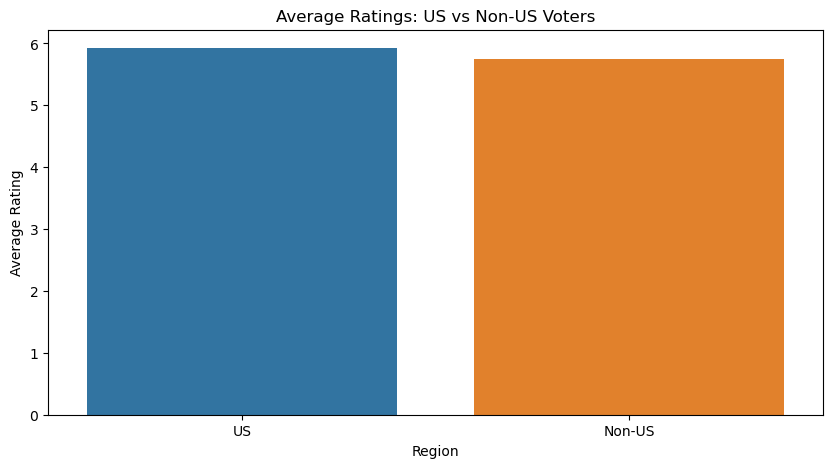

In [31]:
# Plot the average ratings comparison
ratings_data = {
    'Region': ['US', 'Non-US'],
    'Average Rating': [us_avg_rating, non_us_avg_rating]
}
ratings_df = pd.DataFrame(ratings_data)

plt.figure(figsize=(10, 5))
sns.barplot(x='Region', y='Average Rating', data=ratings_df)
plt.title('Average Ratings: US vs Non-US Voters')
plt.ylabel('Average Rating')
plt.show()

### The total vote counts comparison

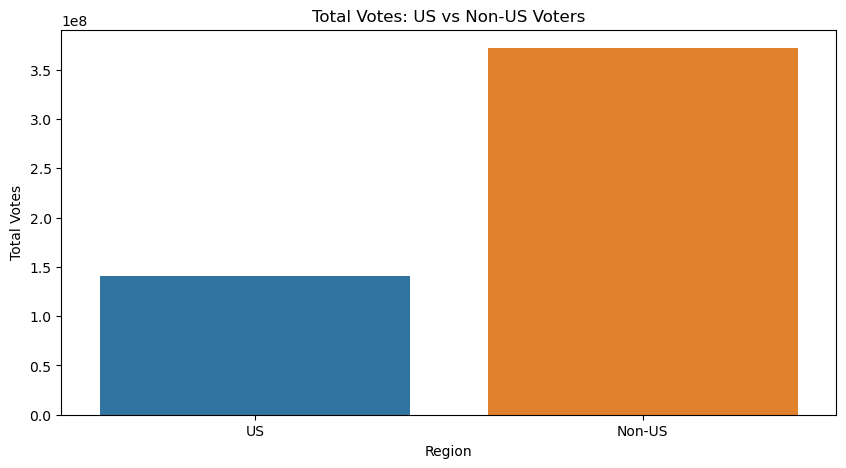

In [32]:
votes_data = {
    'Region': ['US', 'Non-US'],
    'Total Votes': [us_total_votes, non_us_total_votes]
}
votes_df = pd.DataFrame(votes_data)

plt.figure(figsize=(10, 5))
sns.barplot(x='Region', y='Total Votes', data=votes_df)
plt.title('Total Votes: US vs Non-US Voters')
plt.ylabel('Total Votes')
plt.show()

In [36]:
df_imdbmov = pd.read_csv('IMDbmovies.csv')

df_imdbmov.head()

C:\Users\gadoc\AppData\Local\Temp\ipykernel_25832\1838944879.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_imdbmov = pd.read_csv('IMDbmovies.csv')


,imdb_title_id,title,original_title,year,date_published,genre,duration,country,language,director,...,actors,description,avg_vote,votes,budget,usa_gross_income,worlwide_gross_income,metascore,reviews_from_users,reviews_from_critics
0,tt0000009,Miss Jerry,Miss Jerry,1894,1894-10-09,Romance,45,USA,NaN,Alexander Black,...,"Blanche Bayliss, William Courtenay, Chauncey D...",The adventures of a female reporter in the 1890s.,5.9,154,NaN,NaN,NaN,NaN,1.0,2.0
1,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,26-12-1906,"Biography, Crime, Drama",70,Australia,NaN,Charles Tait,...,"Elizabeth Tait, John Tait, Norman Campbell, Be...",True story of notorious Australian outlaw Ned ...,6.1,589,$ 2250,NaN,NaN,NaN,7.0,7.0
2,tt0001892,Den sorte drøm,Den sorte drøm,1911,19-08-1911,Drama,53,"Germany, Denmark",NaN,Urban Gad,...,"Asta Nielsen, Valdemar Psilander, Gunnar Helse...",Two men of high rank are both wooing the beaut...,5.8,188,NaN,NaN,NaN,NaN,5.0,2.0
3,tt0002101,Cleopatra,Cleopatra,1912,13-11-1912,"Drama, History",100,USA,English,Charles L. Gaskill,...,"Helen Gardner, Pearl Sindelar, Miss Fielding, ...",The fabled queen of Egypt's affair with Roman ...,5.2,446,$ 45000,NaN,NaN,NaN,25.0,3.0
4,tt0002130,L'Inferno,L'Inferno,1911,06-03-1911,"Adventure, Drama, Fantasy",68,Italy,Italian,"Francesco Bertolini, Adolfo Padovan",...,"Salvatore Papa, Arturo Pirovano, Giuseppe de L...",Loosely adapted from Dante's Divine Comedy and...,7.0,2237,NaN,NaN,NaN,NaN,31.0,14.0


In [37]:
df_imdbmov.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85855 entries, 0 to 85854
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   imdb_title_id          85855 non-null  object 
 1   title                  85855 non-null  object 
 2   original_title         85855 non-null  object 
 3   year                   85855 non-null  object 
 4   date_published         85855 non-null  object 
 5   genre                  85855 non-null  object 
 6   duration               85855 non-null  int64  
 7   country                85791 non-null  object 
 8   language               84954 non-null  object 
 9   director               85768 non-null  object 
 10  writer                 84283 non-null  object 
 11  production_company     81400 non-null  object 
 12  actors                 85786 non-null  object 
 13  description            83740 non-null  object 
 14  avg_vote               85855 non-null  float64
 15  vo

In [38]:
df_imdbmov = df_imdbmov.drop_duplicates()

In [39]:
df_imdbmov.shape


(85855, 22)

## Collaborative Filtering with IMDb Datasets

Join the Datasets: Use the imdb_title_id column to merge the IMDb movies dataset with the IMDb ratings dataset. This allows us to have a comprehensive dataset containing both movie metadata and user ratings.

In [49]:
merged_df = pd.merge(df_imdbrate, df_imdbmov, on='imdb_title_id')

In [50]:
merged_df.head()

,imdb_title_id,weighted_average_vote,total_votes,mean_vote,median_vote,votes_10,votes_9,votes_8,votes_7,votes_6,...,actors,description,avg_vote,votes,budget,usa_gross_income,worlwide_gross_income,metascore,reviews_from_users,reviews_from_critics
0,tt0000009,5.9,154,5.9,6.0,12,4,10,43,28,...,"Blanche Bayliss, William Courtenay, Chauncey D...",The adventures of a female reporter in the 1890s.,5.9,154,NaN,NaN,NaN,NaN,1.0,2.0
1,tt0000574,6.1,589,6.3,6.0,57,18,58,137,139,...,"Elizabeth Tait, John Tait, Norman Campbell, Be...",True story of notorious Australian outlaw Ned ...,6.1,589,$ 2250,NaN,NaN,NaN,7.0,7.0
2,tt0001892,5.8,188,6.0,6.0,6,6,17,44,52,...,"Asta Nielsen, Valdemar Psilander, Gunnar Helse...",Two men of high rank are both wooing the beaut...,5.8,188,NaN,NaN,NaN,NaN,5.0,2.0
3,tt0002101,5.2,446,5.3,5.0,15,8,16,62,98,...,"Helen Gardner, Pearl Sindelar, Miss Fielding, ...",The fabled queen of Egypt's affair with Roman ...,5.2,446,$ 45000,NaN,NaN,NaN,25.0,3.0
4,tt0002130,7.0,2237,6.9,7.0,210,225,436,641,344,...,"Salvatore Papa, Arturo Pirovano, Giuseppe de L...",Loosely adapted from Dante's Divine Comedy and...,7.0,2237,NaN,NaN,NaN,NaN,31.0,14.0


In [64]:
collab_filter_df = merged_df[['imdb_title_id', 'title', 'weighted_average_vote']]

In [65]:
collab_filter_df.head()

,imdb_title_id,title,weighted_average_vote
0,tt0000009,Miss Jerry,5.9
1,tt0000574,The Story of the Kelly Gang,6.1
2,tt0001892,Den sorte drøm,5.8
3,tt0002101,Cleopatra,5.2
4,tt0002130,L'Inferno,7.0


In [70]:
user_item_matrix = combined_df.pivot_table(columns='imdb_title_id', values='weighted_average_vote')

In [71]:
scaler = MinMaxScaler()
user_item_matrix_scaled = scaler.fit_transform(user_item_matrix)

In [72]:
sparse_matrix = csr_matrix(user_item_matrix_scaled)

In [75]:
model_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=20, n_jobs=-1)
model_knn.fit(sparse_matrix)

NearestNeighbors(algorithm='brute', metric='cosine', n_jobs=-1, n_neighbors=20)

In [82]:
def get_similar_movies(movie_code, model_knn, movies_df, user_item_matrix, n_recommendations=10):
    # Find the index of the movie in the user-item matrix
    if movie_code not in user_item_matrix.index:
        return []

    movie_idx = user_item_matrix.index.get_loc(movie_code)
    
    # Find similar movies
    distances, indices = model_knn.kneighbors(user_item_matrix.iloc[movie_idx, :].values.reshape(1, -1), n_neighbors=n_recommendations + 1)
    
    # Get movie indices and their similarity scores
    similar_movie_indices = indices.flatten()
    similar_movie_distances = distances.flatten()
    
    # Get the codes of the similar movies
    similar_movie_codes = user_item_matrix.index[similar_movie_indices]
    
    # Get the titles of the similar movies
    similar_movies = movies_df[movies_df['imdb_title_id'].isin(similar_movie_codes)]['title']
    
    # Exclude the input movie from the results
    similar_movies = similar_movies[similar_movies != movies_df[movies_df['imdb_title_id'] == movie_code]['title'].values[0]]
    
    return similar_movies

In [87]:
movie_code = 'tt0468569'
recommended_movies = get_similar_movies(movie_code, model_knn, df_imdbmov, user_item_matrix)

# Print recommended movies
print(f"Recommended movies similar to '{df_imdbmov[df_imdbmov['imdb_title_id'] == movie_code]['title'].values[0]}':")
for idx, movie in enumerate(recommended_movies, start=1):
    print(f"{idx}. {movie}")

Recommended movies similar to 'Il cavaliere oscuro':
